# FIFA World Cup 2026 — Linear Regression 2.1
## 02. Exploratory Data Analysis (EDA)

**Objective:** Explore home-team goal difference and the eight existing pre-match predictors before regression modelling. 

**Data policy:** Use the output of the Data Preparation notebook. 

## Step 1 — Load and inspect the prepared dataset

In [17]:
from pathlib import Path #Import the Path class from the pathlib module for handling file paths
import pandas as pd   #Import the pandas library for data manipulation and analysis
import numpy as np   #Import the numpy library for numerical operations
import matplotlib.pyplot as plt   #Import the matplotlib library for data visualization

pd.set_option("display.max_columns", None)  #Ensure that all columns are displayed when printing the DataFrame
file_path = Path("Regression_2_1_Prepared_Data.csv")  #Define the file path for the prepared data CSV file
if not file_path.exists():  #Check if the file exists at the specified path, If not, raise an error
    raise FileNotFoundError("Run the ORIGINAL 01_Data_Preparation_Regression_2_1 notebook first to create Regression_2_1_Prepared_Data.csv.")
df = pd.read_csv(file_path, parse_dates=["date"])  #Read the CSV file into a DataFrame, parsing the "date" column as datetime
print("Loaded:", file_path.name)  #Print the name of the loaded file
print("Shape:", df.shape)  #Print the shape of the DataFrame
display(df.head())  #Display the first few rows of the DataFrame

Loaded: Regression_2_1_Prepared_Data.csv
Shape: (104, 14)


,match_id,date,Round_Number,Home_Team,Away_Team,Team_prior_matches,Opponent_prior_matches,Team_prior_goals_scored_avg,Opponent_prior_goals_scored_avg,Team_rest_days,Opponent_rest_days,Team_prior_win_rate,Opponent_prior_win_rate,goal_difference
0,1,2026-06-11 19:00:00.000002931,1,Mexico,South Africa,16,10,1.5,1.5,7,13,0.4,0.4,2
1,2,2026-06-12 01:59:59.999997068,1,South Korea,Czech Republic,7,7,1.9,2.0,1,12,0.7,0.6,1
2,3,2026-06-12 19:00:00.000002931,1,Canada,Bosnia and Herzegovina,11,4,1.0,1.1,7,14,0.3,0.3,0
3,4,2026-06-13 01:00:00.000002931,1,United States,Paraguay,17,2,2.2,1.4,1,8,0.6,0.7,3
4,8,2026-06-13 19:00:00.000002931,1,Qatar,Switzerland,10,5,0.9,2.7,7,13,0.1,0.6,0


In [18]:
target = "goal_difference"  #Define the target variable for the regression model
features = [  #Define the predictor variables for the regression model
    "Team_prior_matches", "Opponent_prior_matches",
    "Team_prior_goals_scored_avg", "Opponent_prior_goals_scored_avg",
    "Team_rest_days", "Opponent_rest_days",
    "Team_prior_win_rate", "Opponent_prior_win_rate"
]
assert len(features) == 8 and all(c in df.columns for c in features + [target])  #Ensure that there are exactly 8 features and all required columns exist in the DataFrame
print("Target:", target)  #Print the target variable
print("Predictors:", *features, sep="\n- ")  #Print the predictor variables

Target: goal_difference
Predictors:
- Team_prior_matches
- Opponent_prior_matches
- Team_prior_goals_scored_avg
- Opponent_prior_goals_scored_avg
- Team_rest_days
- Opponent_rest_days
- Team_prior_win_rate
- Opponent_prior_win_rate


In [19]:
print("Rows:", len(df))                  #Display the number of rows in the DataFrame
print("Unique match IDs:", df["match_id"].nunique())  #Display the number of unique match IDs
print("Duplicate match IDs:", df["match_id"].duplicated().sum())  #Display the number of duplicate match IDs
print("Teams represented:", len(set(df["Home_Team"]).union(df["Away_Team"])))  #Display the number of unique teams represented
print("Date range:", df["date"].min(), "to", df["date"].max())  #Display the range of dates in the dataset
display(df.dtypes.to_frame("Data type"))  #Display the data types of each column in the DataFrame

Rows: 104
Unique match IDs: 104
Duplicate match IDs: 0
Teams represented: 48
Date range: 2026-06-11 19:00:00.000002931 to 2026-07-19 19:00:00.000002931


,Data type
match_id,int64
date,datetime64[ns]
Round_Number,str
Home_Team,str
Away_Team,str
Team_prior_matches,int64
Opponent_prior_matches,int64
Team_prior_goals_scored_avg,float64
Opponent_prior_goals_scored_avg,float64
Team_rest_days,int64


In [20]:
missing = df[features + [target]].isna().sum().to_frame("Missing values")  #Calculate the number of missing values for each feature and the target variable
display(missing)  #Display the number of missing values for each feature and the target variable
print("Rows with at least one missing predictor:", df[features].isna().any(axis=1).sum())  #Display the number of rows with at least one missing predictor

,Missing values
Team_prior_matches,0
Opponent_prior_matches,0
Team_prior_goals_scored_avg,0
Opponent_prior_goals_scored_avg,0
Team_rest_days,0
Opponent_rest_days,0
Team_prior_win_rate,0
Opponent_prior_win_rate,0
goal_difference,0


Rows with at least one missing predictor: 0


## Step 2 — Descriptive statistics and target distribution

Goal difference is **signed**: positive means a home-team win, zero a draw, and negative an away-team win. Unlike goals scored, it can be negative.

In [21]:
display(df[features + [target]].describe().T) #Display the summary statistics for each feature and the target variable
summary = pd.DataFrame({
    "Count": df[features + [target]].count(),
    "Missing": df[features + [target]].isna().sum(),
    "Mean": df[features + [target]].mean(),
    "Median": df[features + [target]].median(),
    "Std dev": df[features + [target]].std(),
    "Skewness": df[features + [target]].skew()
})
display(summary.round(3))  #Display the summary statistics for each feature and the target variable. This includes count, missing values, mean, median, standard deviation, and skewness.

,count,mean,std,min,25%,50%,75%,max
Team_prior_matches,104.0,8.067308,3.484402,2.0,6.000,7.0,9.000,21.0
Opponent_prior_matches,104.0,8.192308,4.126817,2.0,6.000,7.0,10.000,22.0
Team_prior_goals_scored_avg,104.0,2.136538,0.695067,0.9,1.575,2.2,2.600,3.7
Opponent_prior_goals_scored_avg,104.0,1.981731,0.664899,0.8,1.400,1.9,2.425,3.9
Team_rest_days,104.0,12.740385,35.560968,1.0,1.000,6.0,9.000,254.0
Opponent_rest_days,104.0,16.576923,32.107433,1.0,6.000,8.5,14.000,248.0
Team_prior_win_rate,104.0,0.617308,0.162769,0.1,0.500,0.6,0.700,1.0
Opponent_prior_win_rate,104.0,0.614423,0.165123,0.1,0.500,0.6,0.700,1.0
goal_difference,104.0,0.480769,2.024034,-4.0,-1.000,0.0,2.000,6.0


,Count,Missing,Mean,Median,Std dev,Skewness
Team_prior_matches,104,0,8.067,7.0,3.484,1.351
Opponent_prior_matches,104,0,8.192,7.0,4.127,1.668
Team_prior_goals_scored_avg,104,0,2.137,2.2,0.695,0.264
Opponent_prior_goals_scored_avg,104,0,1.982,1.9,0.665,0.426
Team_rest_days,104,0,12.740,6.0,35.561,6.087
Opponent_rest_days,104,0,16.577,8.5,32.107,5.237
Team_prior_win_rate,104,0,0.617,0.6,0.163,-0.464
Opponent_prior_win_rate,104,0,0.614,0.6,0.165,-0.565
goal_difference,104,0,0.481,0.0,2.024,0.258


In [22]:
values = df[target].dropna()  #Drop missing values from the target variable before calculating statistics
print("Mean goal difference:", round(values.mean(), 3))  #Display the mean of the target variable
print("Median:", values.median())  #Display the median of the target variable
print("Variance:", round(values.var(), 3))  #Display the variance of the target variable
print("Standard deviation:", round(values.std(), 3))  #Display the standard deviation of the target variable
print("Skewness:", round(values.skew(), 3))  #Display the skewness of the target variable
print("Home wins:", (values > 0).sum(), "| Draws:", (values == 0).sum(), "| Away wins:", (values < 0).sum())  #Display the count of home wins, draws, and away wins
display(values.value_counts().sort_index().rename_axis("Goal difference").to_frame("Matches"))  #Display the frequency of each goal difference value

Mean goal difference: 0.481
Median: 0.0
Variance: 4.097
Standard deviation: 2.024
Skewness: 0.258
Home wins: 50 | Draws: 24 | Away wins: 30


,Matches
Goal difference,
-4,2
-3,6
-2,8
-1,14
0,24
1,21
2,15
3,7
4,3


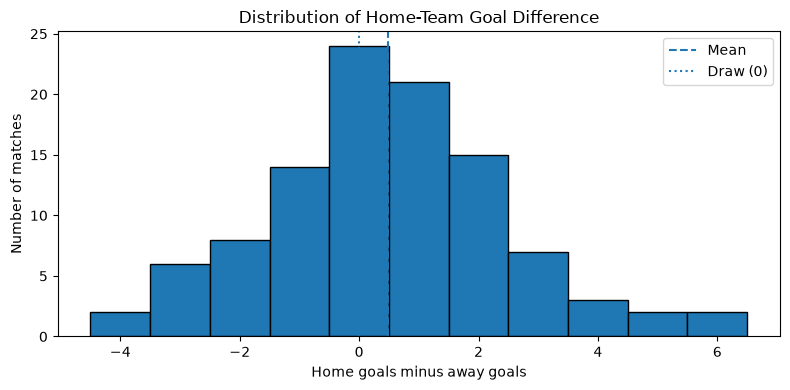

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\2254188948.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the target variable


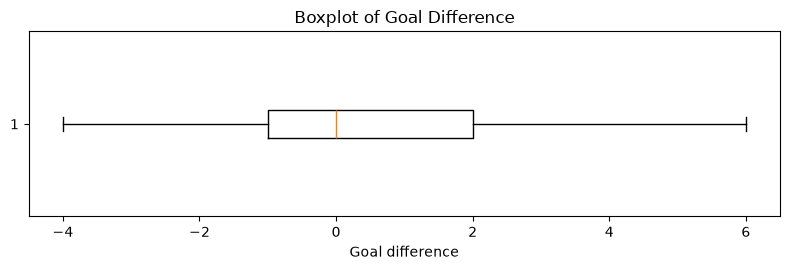

In [23]:
plt.figure(figsize=(8, 4))    #Create a figure for the histogram with specified size
plt.hist(values, bins=np.arange(values.min()-0.5, values.max()+1.5, 1), edgecolor="black")  #Create a histogram of the target variable with specified bins and edge color
plt.axvline(values.mean(), linestyle="--", label="Mean")  #Add a vertical line at the mean of the target variable
plt.axvline(0, linestyle=":", label="Draw (0)")  #Add a vertical line at 0 to indicate draws
plt.title("Distribution of Home-Team Goal Difference")  #Set the title of the histogram
plt.xlabel("Home goals minus away goals")  #Set the x-axis label of the histogram
plt.ylabel("Number of matches")  #Set the y-axis label of the histogram
plt.legend()    #Display the legend for the histogram
plt.tight_layout()  #Adjust the layout to prevent overlapping elements
plt.show()  #Display the histogram

plt.figure(figsize=(8, 2.8))  #Create a figure for the boxplot with specified size
plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the target variable
plt.title("Boxplot of Goal Difference")  #Set the title of the boxplot
plt.xlabel("Goal difference")  #Set the x-axis label of the boxplot
plt.tight_layout()  #Adjust the layout to prevent overlapping elements
plt.show()  #Display the boxplot

## Step 3 — Predictor distributions and possible outliers

Inspect the spread of all eight variables. An unusual value is not automatically an error; retain observations unless there is evidence that they are invalid.

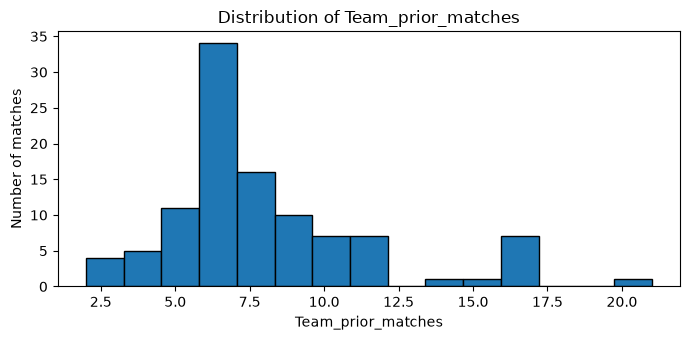

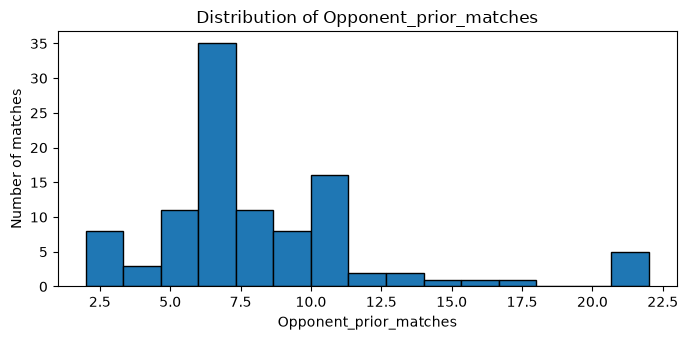

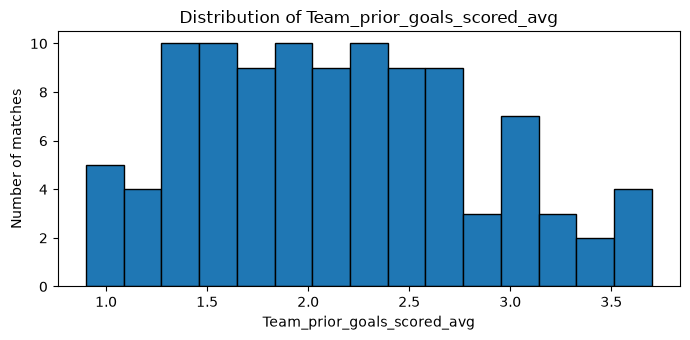

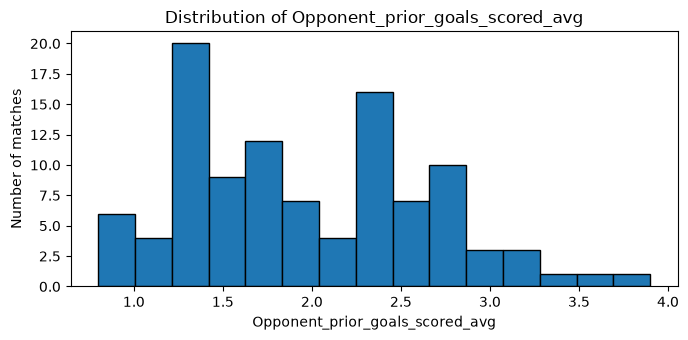

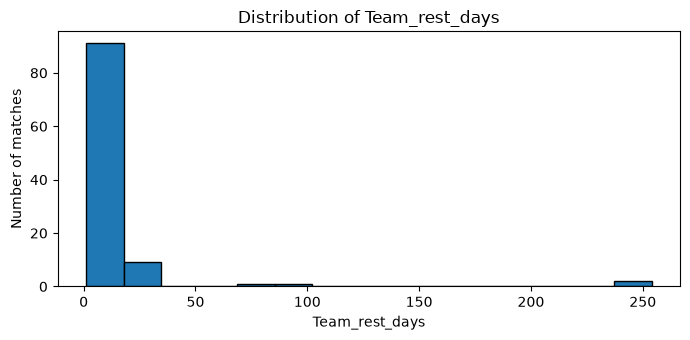

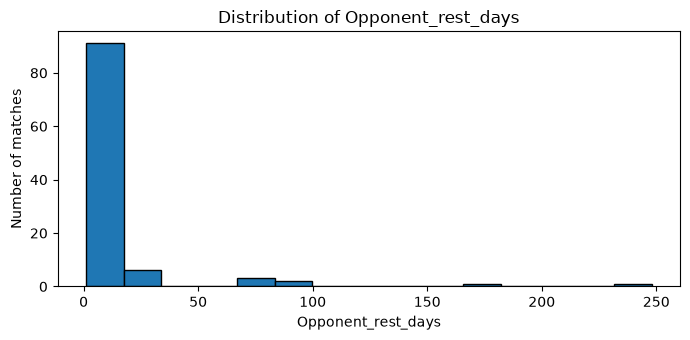

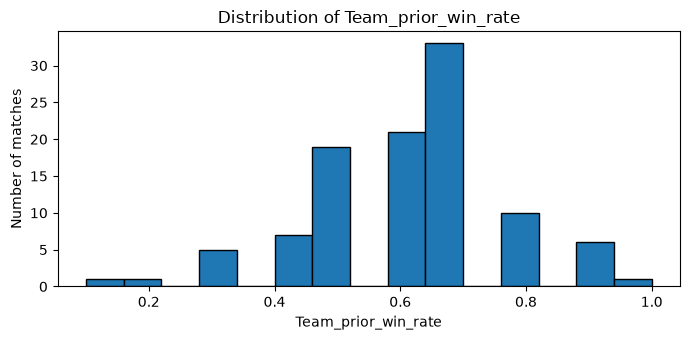

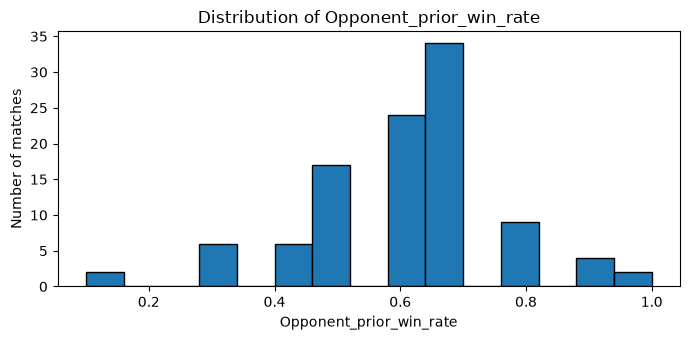

In [24]:
for feature in features:  #Iterate over each feature to create histograms
    values = df[feature].dropna()  #Drop missing values from the feature before creating the histogram
    plt.figure(figsize=(7, 3.5))  #Create a figure for the histogram with specified size
    plt.hist(values, bins=15, edgecolor="black")  #Create a histogram of the feature with specified bins and edge color
    plt.title(f"Distribution of {feature}")  #Set the title of the histogram
    plt.xlabel(feature)  #Set the x-axis label of the histogram
    plt.ylabel("Number of matches")  #Set the y-axis label of the histogram
    plt.tight_layout()  #Adjust the layout to prevent overlapping elements
    plt.show()  #Display the histogram

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


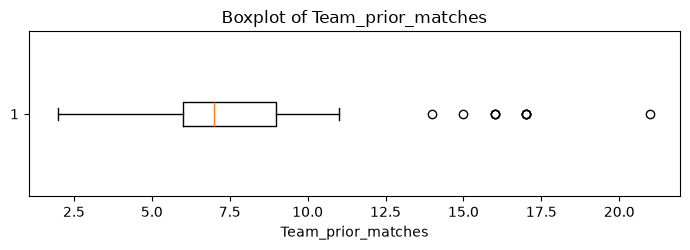

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


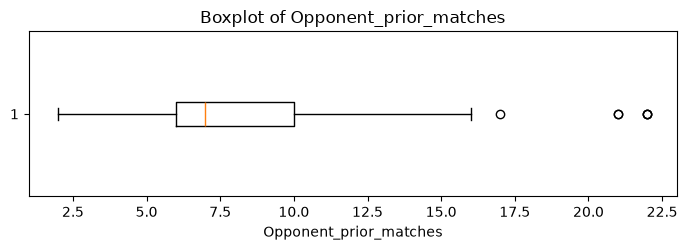

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


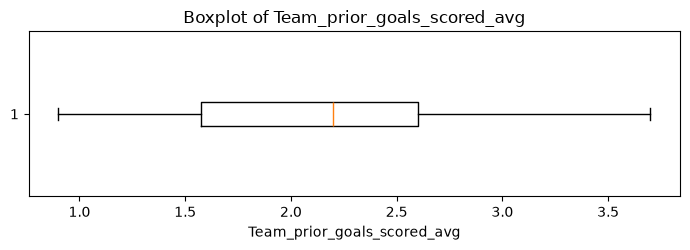

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


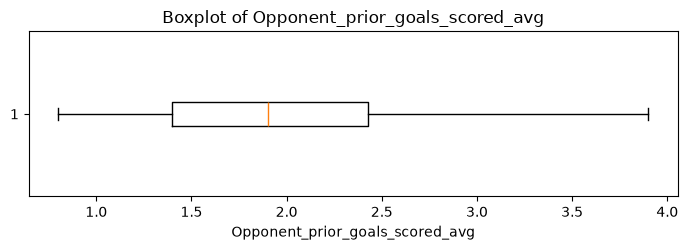

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


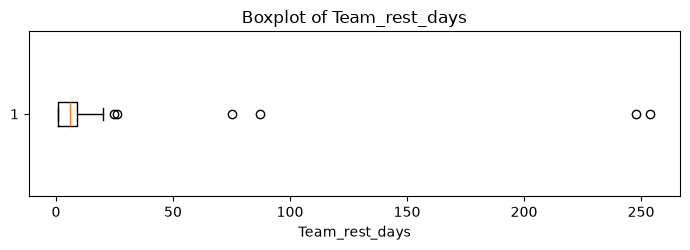

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


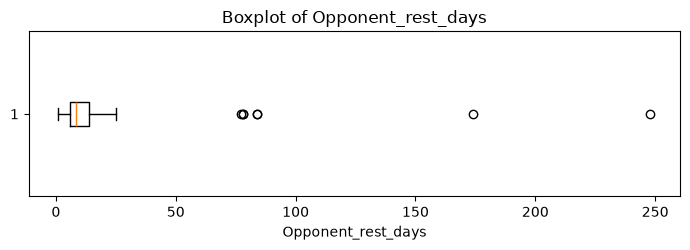

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


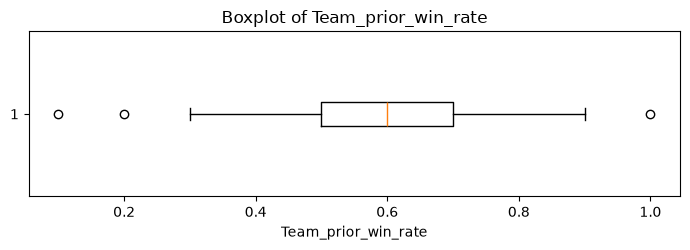

C:\Users\jelag\AppData\Local\Temp\ipykernel_27380\3857873448.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature


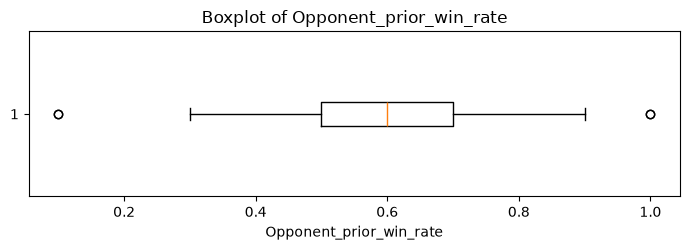

In [25]:
for feature in features:   #Iterate over each feature to create boxplots    
    values = df[feature].dropna()  #Drop missing values from the feature before creating the boxplot
    if len(values):
        plt.figure(figsize=(7, 2.6))  #Create a figure for the boxplot with specified size
        plt.boxplot(values, vert=False)  #Create a horizontal boxplot of the feature
        plt.title(f"Boxplot of {feature}")  #Set the title of the boxplot
        plt.xlabel(feature)  #Set the x-axis label of the boxplot
        plt.tight_layout()  #Adjust the layout to prevent overlapping elements
        plt.show()  #Display the boxplot

In [26]:
outliers = []  #Initialize an empty list to store outlier information for each feature
for feature in features:  #Iterate over each feature to calculate outlier information
    values = df[feature].dropna()  #Drop missing values from the feature before calculating outliers
    q1, q3 = values.quantile([0.25, 0.75])  #Calculate the first and third quartiles
    iqr = q3 - q1  #Calculate the interquartile range
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr  #Calculate the lower and upper fences for outliers
    count = ((values < lower) | (values > upper)).sum()  #Count the number of possible outliers
    outliers.append({"Predictor": feature, "Lower fence": lower, "Upper fence": upper, "Possible outliers": count})  #Store the outlier information for the feature
display(pd.DataFrame(outliers).round(3))  #Display the outlier information for all features rounded to 3 decimal places

,Predictor,Lower fence,Upper fence,Possible outliers
0,Team_prior_matches,1.500,13.500,10
1,Opponent_prior_matches,0.000,16.000,6
2,Team_prior_goals_scored_avg,0.038,4.138,0
3,Opponent_prior_goals_scored_avg,-0.137,3.962,0
4,Team_rest_days,-11.000,21.000,6
5,Opponent_rest_days,-6.000,26.000,7
6,Team_prior_win_rate,0.200,1.000,3
7,Opponent_prior_win_rate,0.200,1.000,4


## Step 4 — Missing values and relationships

We report missing observations without imputing them. Correlations use complete pairs or complete cases as indicated; neither procedure changes the prepared dataset.

In [27]:
missing_rows = df.loc[df[features].isna().any(axis=1), ["match_id", "date", "Home_Team", "Away_Team"] + features]  #Identify rows with missing predictor values
print("Matches with missing predictor values:", len(missing_rows))  #Print the number of matches with missing predictor values
display(missing_rows.head(30))  #Display the first 30 rows with missing predictor values
complete_eda = df.dropna(subset=features + [target]).copy()  #Create a DataFrame with complete cases for correlation analysis
print("Complete-case matches for correlation:", len(complete_eda))  #Print the number of complete-case matches for correlation analysis

Matches with missing predictor values: 0


,match_id,date,Home_Team,Away_Team,Team_prior_matches,Opponent_prior_matches,Team_prior_goals_scored_avg,Opponent_prior_goals_scored_avg,Team_rest_days,Opponent_rest_days,Team_prior_win_rate,Opponent_prior_win_rate


Complete-case matches for correlation: 104


,Team_prior_matches,Opponent_prior_matches,Team_prior_goals_scored_avg,Opponent_prior_goals_scored_avg,Team_rest_days,Opponent_rest_days,Team_prior_win_rate,Opponent_prior_win_rate,goal_difference
Team_prior_matches,1.000,-0.004,-0.123,-0.074,-0.274,-0.047,-0.074,-0.074,0.064
Opponent_prior_matches,-0.004,1.000,0.003,0.040,-0.063,-0.131,-0.053,0.040,-0.126
Team_prior_goals_scored_avg,-0.123,0.003,1.000,0.004,-0.135,-0.084,0.563,0.192,0.090
Opponent_prior_goals_scored_avg,-0.074,0.040,0.004,1.000,-0.068,0.009,0.032,0.586,-0.292
Team_rest_days,-0.274,-0.063,-0.135,-0.068,1.000,-0.032,-0.031,-0.060,0.068
Opponent_rest_days,-0.047,-0.131,-0.084,0.009,-0.032,1.000,-0.098,0.044,0.092
Team_prior_win_rate,-0.074,-0.053,0.563,0.032,-0.031,-0.098,1.000,0.258,0.157
Opponent_prior_win_rate,-0.074,0.040,0.192,0.586,-0.060,0.044,0.258,1.000,-0.282
goal_difference,0.064,-0.126,0.090,-0.292,0.068,0.092,0.157,-0.282,1.000


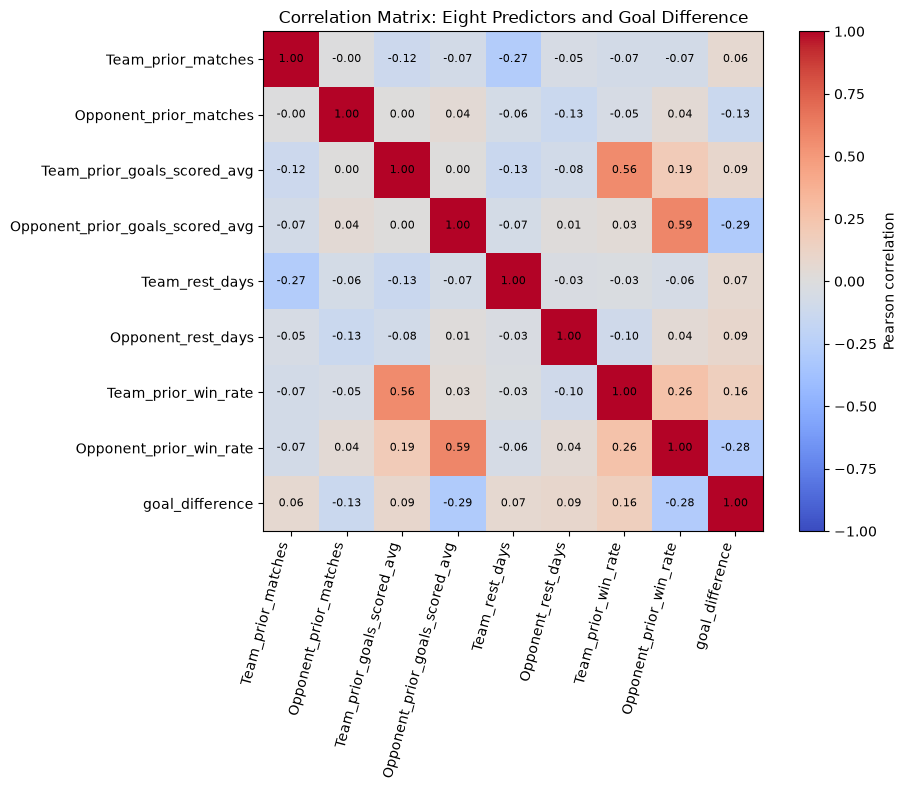

In [28]:
correlation_matrix = complete_eda[features + [target]].corr() #Calculate the Pearson correlation matrix for the complete-case dataset
display(correlation_matrix.round(3))  #Display the correlation matrix rounded to 3 decimal places

plt.figure(figsize=(10, 8))  #Plot a figure for the correlation matrix heatmap with specified size
plt.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")  #Display the correlation matrix as a heatmap
plt.colorbar(label="Pearson correlation")  #Add a colorbar with label
labels = features + [target]  #Define the labels for the axes
plt.xticks(range(len(labels)), labels, rotation=75, ha="right")  #Set the x-axis ticks and labels
plt.yticks(range(len(labels)), labels)  #Set the y-axis ticks and labels
for i in range(len(labels)):  #Iterate over the rows of the correlation matrix
    for j in range(len(labels)):  #Iterate over the columns of the correlation matrix
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)  #Annotate each cell with the correlation value
plt.title("Correlation Matrix: Eight Predictors and Goal Difference")  #Set the title of the heatmap
plt.tight_layout()  #Adjust the layout to prevent overlapping elements
plt.show()  #Display the heatmap

In [29]:
predictor_corr = complete_eda[features].corr() #Calculate the Pearson correlation matrix for the predictor variables
strong_pairs = [] #Initialize an empty list to store strong predictor pairs
for i in range(len(features)): #Iterate over the predictor variables to find strong correlations
    for j in range(i + 1, len(features)):  #Iterate over the remaining predictor variables to find strong correlations
        r = predictor_corr.iloc[i, j]  #Get the correlation coefficient for the predictor pair
        if abs(r) >= 0.7:  #Check if the absolute correlation is strong
            strong_pairs.append({"Predictor 1": features[i], "Predictor 2": features[j], "Correlation": r})  #Store the strong predictor pair information
print("Predictor pairs with |r| >= 0.70:")  #Print a header for the strong predictor pairs
display(pd.DataFrame(strong_pairs, columns=["Predictor 1", "Predictor 2", "Correlation"]))  #Display the strong predictor pairs in a DataFrame

Predictor pairs with |r| >= 0.70:


,Predictor 1,Predictor 2,Correlation


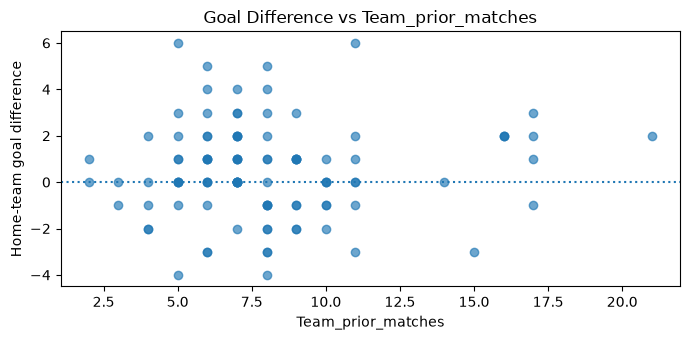

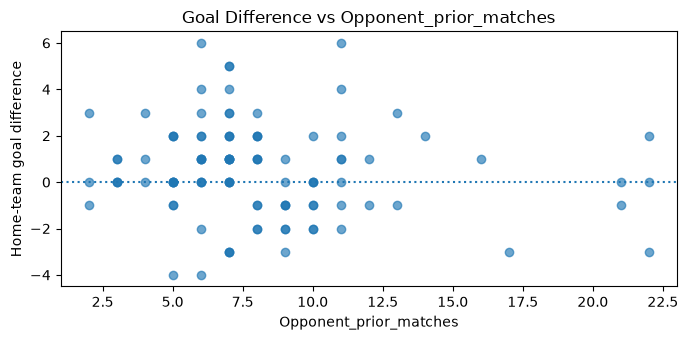

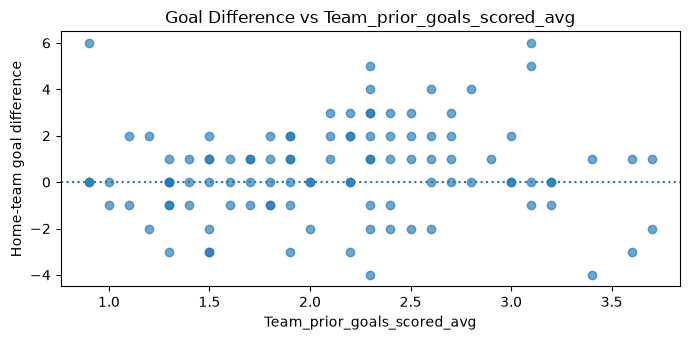

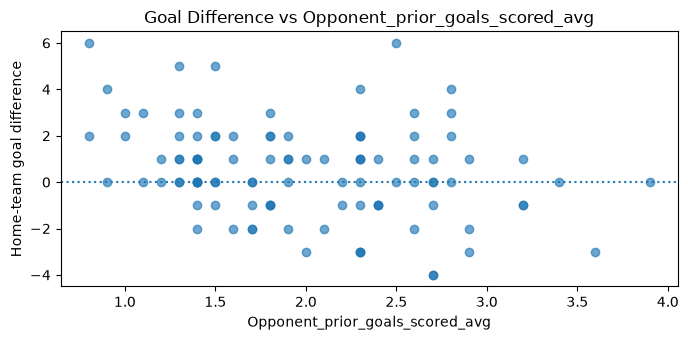

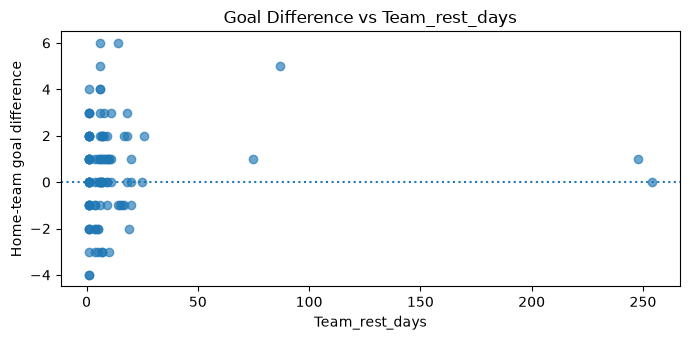

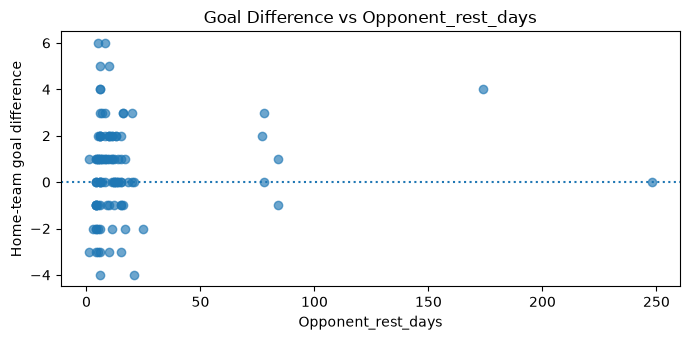

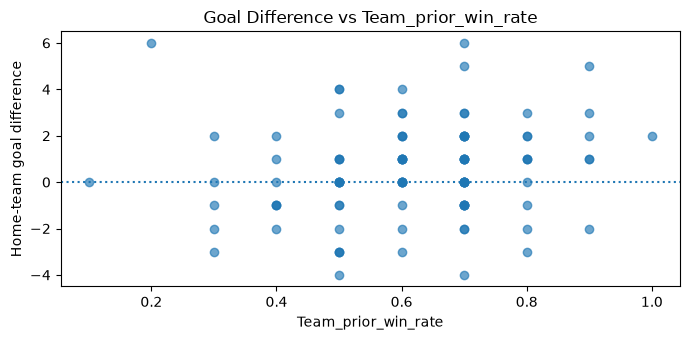

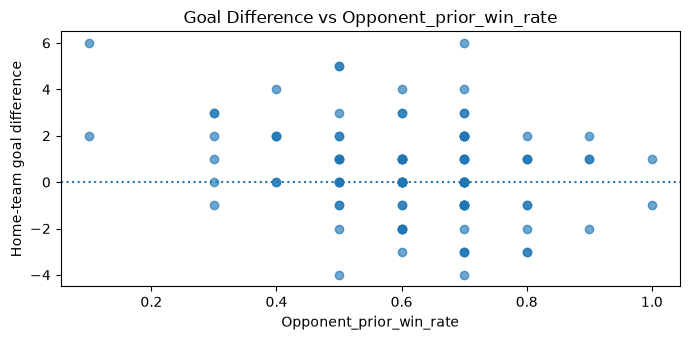

In [30]:
for feature in features:  #Iterate over each predictor feature to create scatter plots against the target variable
    pair = df[[feature, target]].dropna()  #Create a DataFrame with non-missing values for the current feature and target
    plt.figure(figsize=(7, 3.5))  #Set the figure size for the scatter plot
    plt.scatter(pair[feature], pair[target], alpha=0.65)  #Create a scatter plot of the feature against the target
    plt.axhline(0, linestyle=":")  #Add a horizontal line at y=0 for reference
    plt.title(f"Goal Difference vs {feature}")  #Set the title of the scatter plot
    plt.xlabel(feature)  #Set the x-axis label
    plt.ylabel("Home-team goal difference")  #Set the y-axis label
    plt.tight_layout()  #Adjust the layout to prevent overlapping elements
    plt.show()  #Display the scatter plot

In [31]:
target_corr = correlation_matrix[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False)  #Sort the predictor correlations with the target by absolute strength
print("Predictor correlations with goal difference (ordered by absolute strength):")  #Print a header for the sorted predictor correlations
display(target_corr.round(3).to_frame("Pearson r"))  #Display the sorted predictor correlations in a DataFrame rounded to 3 decimal places

Predictor correlations with goal difference (ordered by absolute strength):


,Pearson r
Opponent_prior_goals_scored_avg,-0.292
Opponent_prior_win_rate,-0.282
Team_prior_win_rate,0.157
Opponent_prior_matches,-0.126
Opponent_rest_days,0.092
Team_prior_goals_scored_avg,0.090
Team_rest_days,0.068
Team_prior_matches,0.064


## Step 5 — Final EDA checks and summary



In [32]:
assert len(features) == 8                 #Ensure that there are exactly 8 predictor features
assert df["match_id"].is_unique, "Review repeated match identifiers."  #Ensure that each match has a unique identifier
assert df[target].notna().all(), "The target contains missing values."  #Check that the target variable has no missing values
print("Total matches:", len(df))  #Print the total number of matches in the dataset
print("Complete-case matches:", len(complete_eda))  #Print the number of matches with complete predictor data
print("Rows with missing predictors:", df[features].isna().any(axis=1).sum())  #Print the number of rows with missing predictor values
print("Original dataset unchanged; no missing values filled and no outliers removed.")  #Indicate that the original dataset has not been modified

Total matches: 104
Complete-case matches: 104
Rows with missing predictors: 0
Original dataset unchanged; no missing values filled and no outliers removed.


### EDA interpretation 

The EDA helped us understand the distribution of goal differences and how the eight predictors relate to match results. The dataset had no missing values or duplicate matches, although a few outliers were identified. Opponent average goals scored and win rate showed the strongest negative relationships with goal difference, but the correlations were generally weak. Overall, the data was suitable for regression modelling, although the weak relationships suggest that predicting goal difference may be challenging.

